In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 

warnings.filterwarnings('ignore')

In [3]:

df = pd.read_csv("used_cars.csv")

In [4]:
df

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"
...,...,...,...,...,...,...,...,...,...,...,...,...
4004,Bentley,Continental GT Speed,2023,714 mi.,Gasoline,6.0L W12 48V PDI DOHC Twin Turbo,8-Speed Automatic with Auto-Shift,C / C,Hotspur,None reported,Yes,"$349,950"
4005,Audi,S4 3.0T Premium Plus,2022,"10,900 mi.",Gasoline,349.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,"$53,900"
4006,Porsche,Taycan,2022,"2,116 mi.",NaN,Electric,Automatic,Black,Black,None reported,NaN,"$90,998"
4007,Ford,F-150 Raptor,2020,"33,000 mi.",Gasoline,450.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,A/T,Blue,Black,None reported,Yes,"$62,999"


# EDA 

In [5]:
df.shape

(4009, 12)

In [6]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


In [8]:
df.isnull().sum()

brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

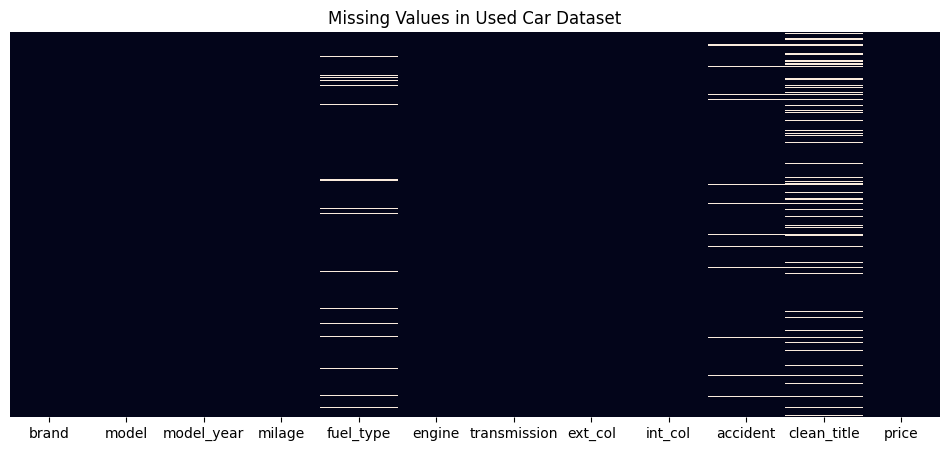

In [17]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in Used Car Dataset")
plt.show()

In [9]:
df.describe()

,model_year
count,4009.000000
mean,2015.515590
std,6.104816
min,1974.000000
25%,2012.000000
50%,2017.000000
75%,2020.000000
max,2024.000000


In [10]:
df.columns

Index(['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine',
       'transmission', 'ext_col', 'int_col', 'accident', 'clean_title',
       'price'],
      dtype='object')

In [11]:
(df.isnull().mean() * 100).round(2)

brand            0.00
model            0.00
model_year       0.00
milage           0.00
fuel_type        4.24
engine           0.00
transmission     0.00
ext_col          0.00
int_col          0.00
accident         2.82
clean_title     14.87
price            0.00
dtype: float64

In [12]:
df.nunique()

brand             57
model           1898
model_year        34
milage          2818
fuel_type          7
engine          1146
transmission      62
ext_col          319
int_col          156
accident           2
clean_title        1
price           1569
dtype: int64

In [13]:
df.select_dtypes(include="object").nunique()

brand             57
model           1898
milage          2818
fuel_type          7
engine          1146
transmission      62
ext_col          319
int_col          156
accident           2
clean_title        1
price           1569
dtype: int64

In [14]:
df.select_dtypes(include="number").columns

Index(['model_year'], dtype='object')

In [15]:
df.select_dtypes(include="object").columns

Index(['brand', 'model', 'milage', 'fuel_type', 'engine', 'transmission',
       'ext_col', 'int_col', 'accident', 'clean_title', 'price'],
      dtype='object')

In [18]:
for col in df.select_dtypes(include="object").columns:
    display(df[col].value_counts(dropna=False).head(10))

brand
Ford             386
BMW              375
Mercedes-Benz    315
Chevrolet        292
Porsche          201
Audi             200
Toyota           199
Lexus            163
Jeep             143
Land             130
Name: count, dtype: int64

model
M3 Base               30
F-150 XLT             24
Corvette Base         22
1500 Laramie          18
Camaro 2SS            17
Wrangler Sport        17
Model Y Long Range    17
Mustang GT Premium    16
911 Carrera           16
M4 Base               15
Name: count, dtype: int64

milage
110,000 mi.    16
45,000 mi.     15
120,000 mi.    13
55,000 mi.     13
92,000 mi.     12
60,000 mi.     12
65,000 mi.     12
40,000 mi.     12
54,000 mi.     12
52,000 mi.     11
Name: count, dtype: int64

fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

engine
2.0L I4 16V GDI DOHC Turbo                               52
355.0HP 5.3L 8 Cylinder Engine Gasoline Fuel             48
420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel             47
–                                                        45
300.0HP 3.0L Straight 6 Cylinder Engine Gasoline Fuel    44
240.0HP 2.0L 4 Cylinder Engine Gasoline Fuel             42
285.0HP 3.6L V6 Cylinder Engine Gasoline Fuel            40
5.7L V8 16V MPFI OHV                                     29
340.0HP 3.0L V6 Cylinder Engine Gasoline Fuel            28
3.6L V6 24V MPFI DOHC                                    28
Name: count, dtype: int64

...

ext_col
Black     905
White     816
Gray      496
Silver    374
Blue      349
Red       261
Green      74
Brown      43
Gold       42
Beige      38
Name: count, dtype: int64

int_col
Black        2025
Beige         538
Gray          472
Brown         157
–             133
White         127
Red           126
Jet Black      59
Ebony          44
Blue           29
Name: count, dtype: int64

accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

clean_title
Yes    3413
NaN     596
Name: count, dtype: int64

price
$15,000    39
$12,000    29
$30,000    28
$16,000    25
$29,000    25
$18,000    24
$17,500    24
$17,000    24
$22,000    24
$32,000    23
Name: count, dtype: int64

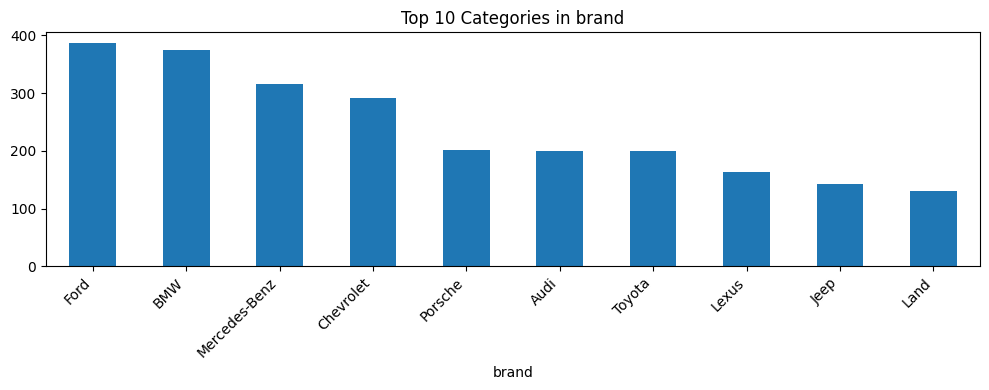

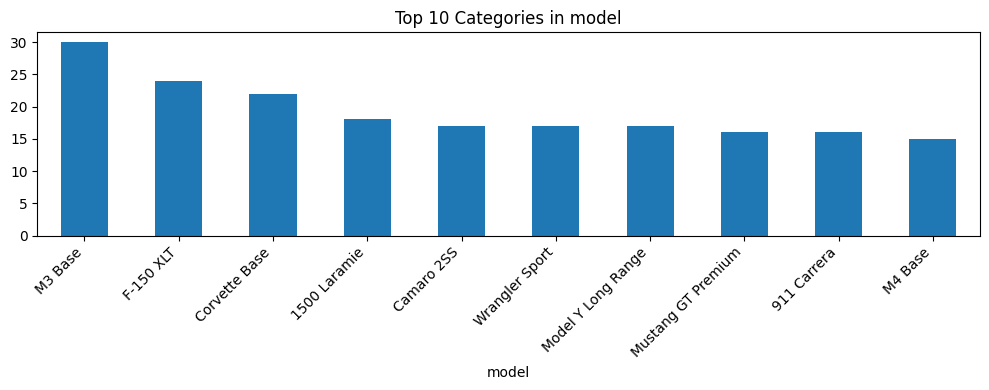

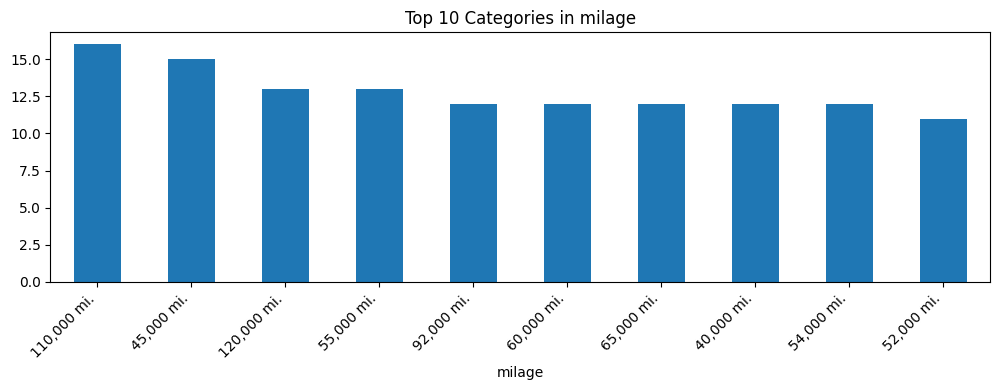

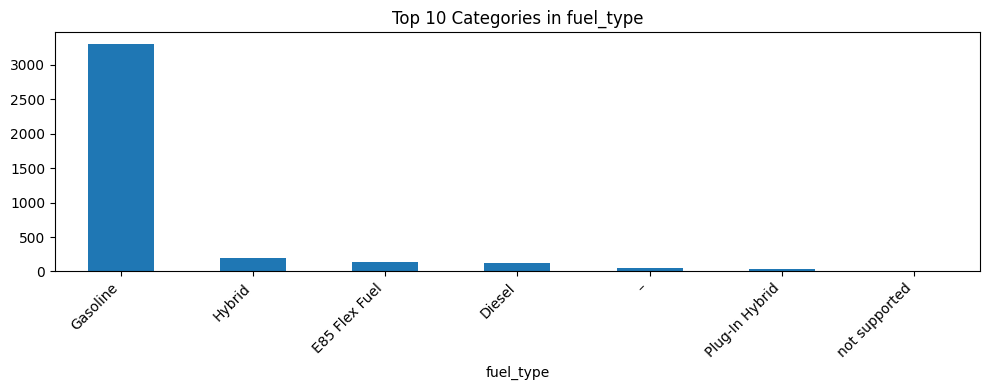

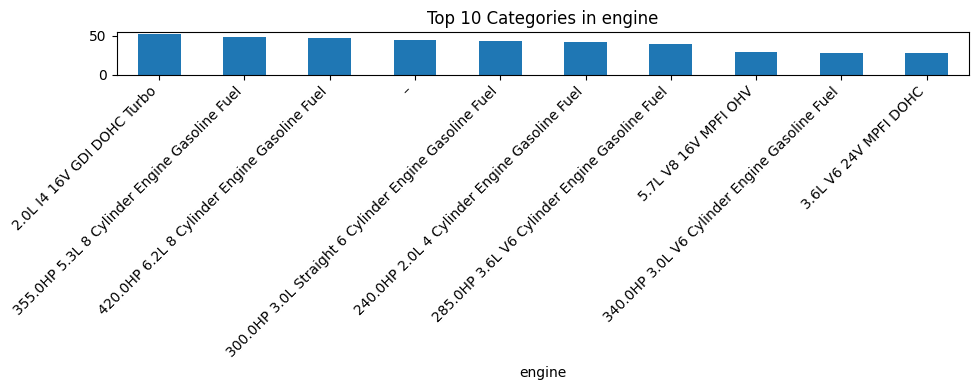

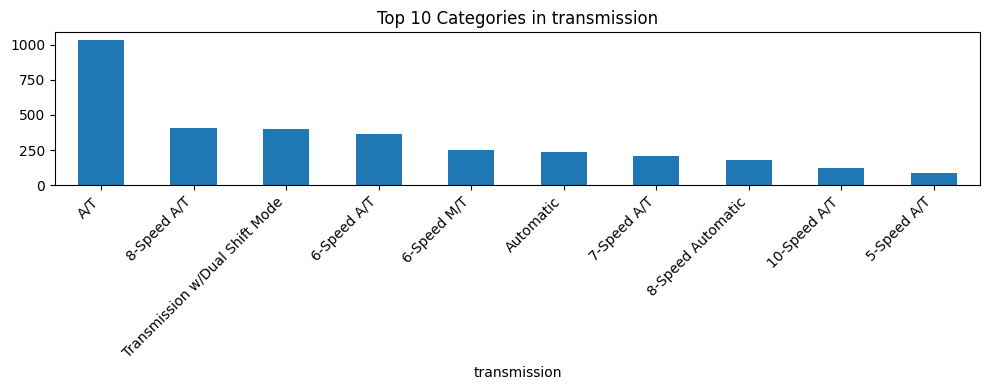

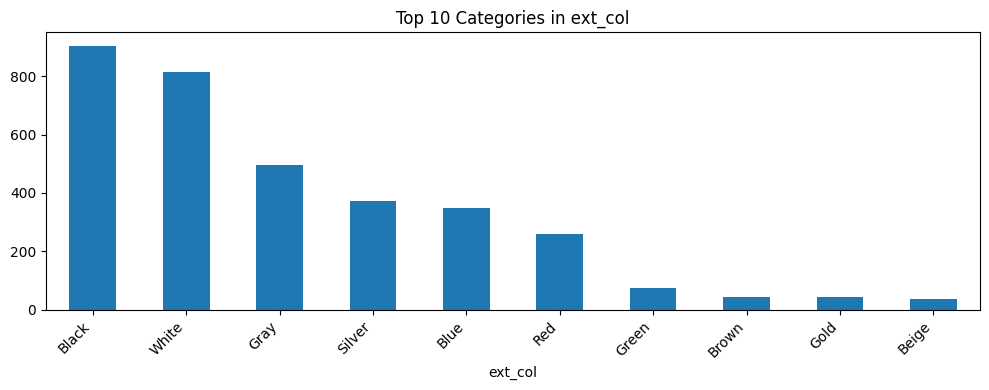

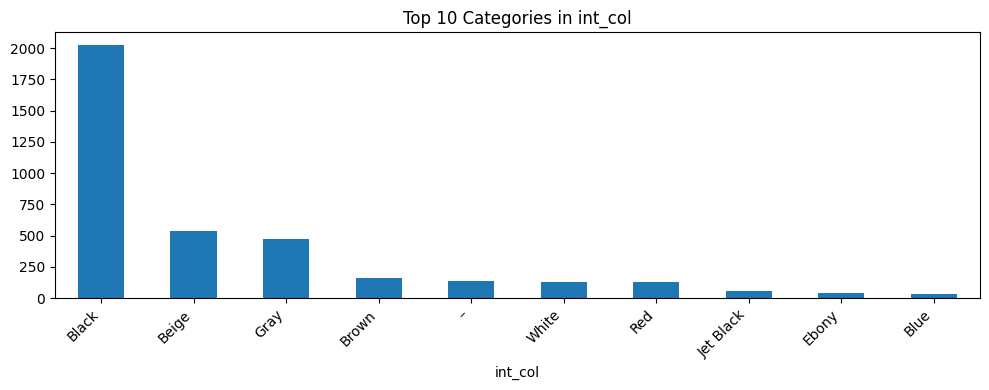

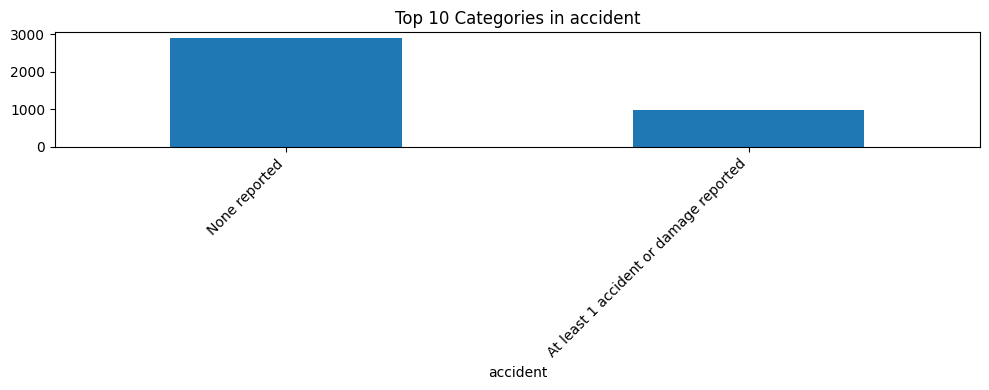

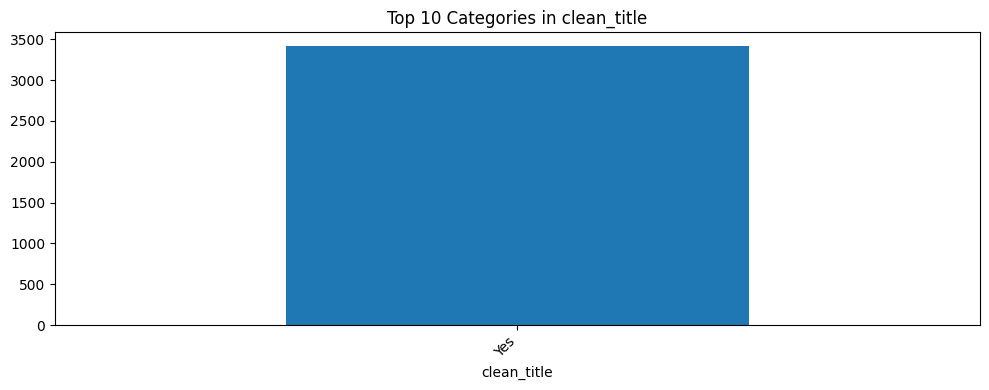

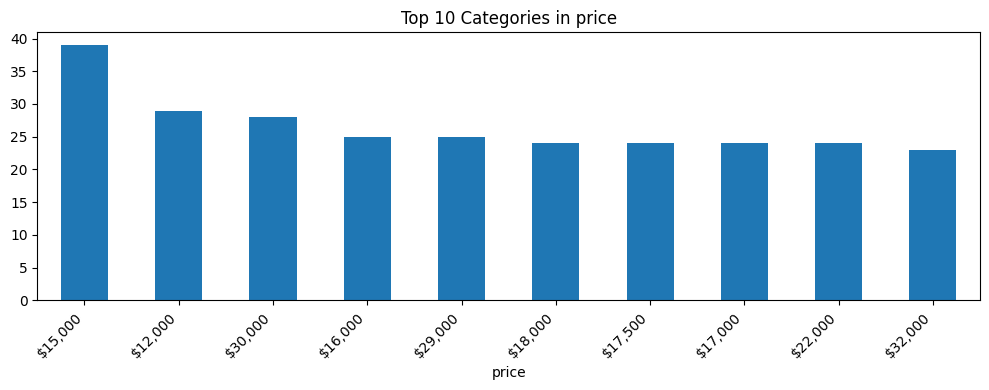

In [19]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    plt.figure(figsize=(10, 4))
    df[col].value_counts().head(10).plot(kind="bar")
    plt.title(f"Top 10 Categories in {col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

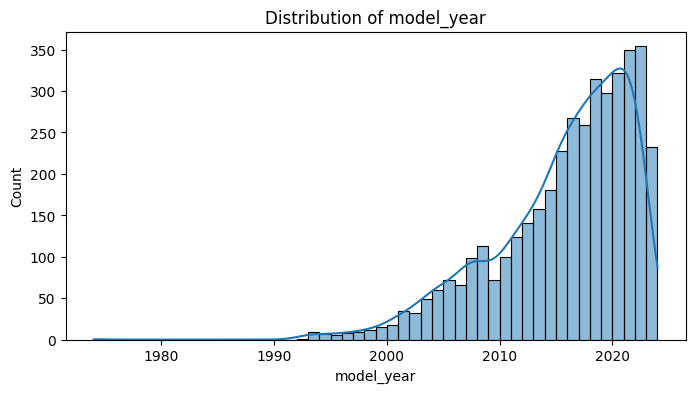

In [20]:
num_cols = df.select_dtypes(include="number").columns

for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

In [21]:
df["price"].head(10)

0    $10,300
1    $38,005
2    $54,598
3    $15,500
4    $34,999
5    $14,798
6    $31,000
7     $7,300
8    $41,927
9    $69,950
Name: price, dtype: object

In [22]:
df["price"].sort_values().head(10)

3046    $1,599,000
229     $1,950,995
1255       $10,000
605        $10,000
1537       $10,000
3438       $10,000
2710       $10,000
1472       $10,000
3413       $10,000
2496       $10,000
Name: price, dtype: object

In [23]:
df["brand"].value_counts().head(15)

brand
Ford             386
BMW              375
Mercedes-Benz    315
Chevrolet        292
Porsche          201
Audi             200
Toyota           199
Lexus            163
Jeep             143
Land             130
Nissan           116
Cadillac         107
GMC               91
RAM               91
Dodge             90
Name: count, dtype: int64

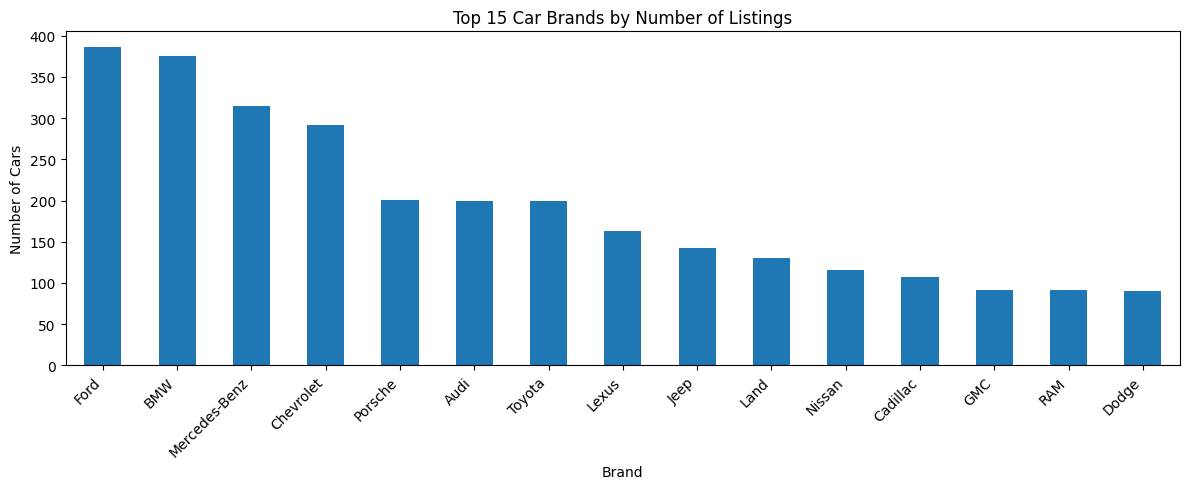

In [24]:
plt.figure(figsize=(12, 5))

df["brand"].value_counts().head(15).plot(kind="bar")

plt.title("Top 15 Car Brands by Number of Listings")
plt.xlabel("Brand")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [26]:
eda_df = df.copy()

In [28]:
eda_df["price"] = pd.to_numeric(
    eda_df["price"]
    .astype("string")
    .str.replace(r"[$,]", "", regex=True)
    .str.strip(),
    errors="coerce"
)

eda_df["milage"] = pd.to_numeric(
    eda_df["milage"]
    .astype("string")
    .str.replace(r"[,\smi]", "", regex=True),
    errors="coerce"
)

eda_df["model_year"] = pd.to_numeric(
    eda_df["model_year"],
    errors="coerce"
)

In [29]:
eda_df[["price", "milage", "model_year"]].dtypes

price           Int64
milage        Float64
model_year      int64
dtype: object

In [30]:
eda_df[["price", "milage", "model_year"]].describe().T

,count,mean,std,min,25%,50%,75%,max
price,4009.0,44553.190322,78710.635554,2000.0,17200.0,31000.0,49990.0,2954083.0
milage,4009.0,64717.55101,52296.599459,100.0,23044.0,52775.0,94100.0,405000.0
model_year,4009.0,2015.51559,6.104816,1974.0,2012.0,2017.0,2020.0,2024.0


In [31]:
eda_df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999


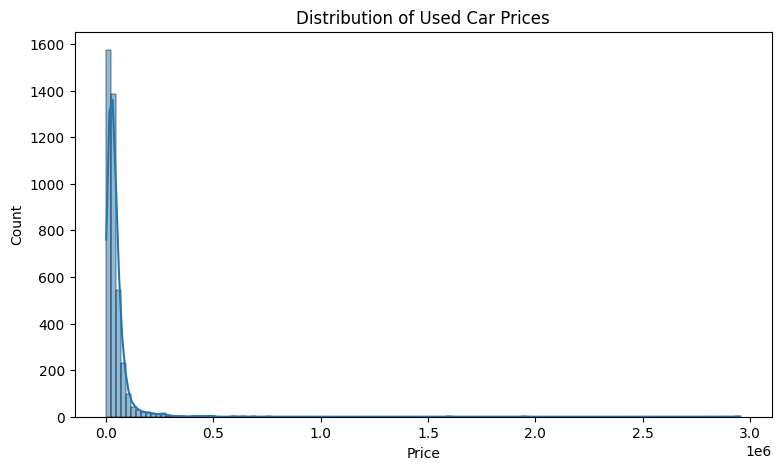

In [32]:
plt.figure(figsize=(9, 5))

sns.histplot(data=eda_df, x="price", kde=True)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price")
plt.show()

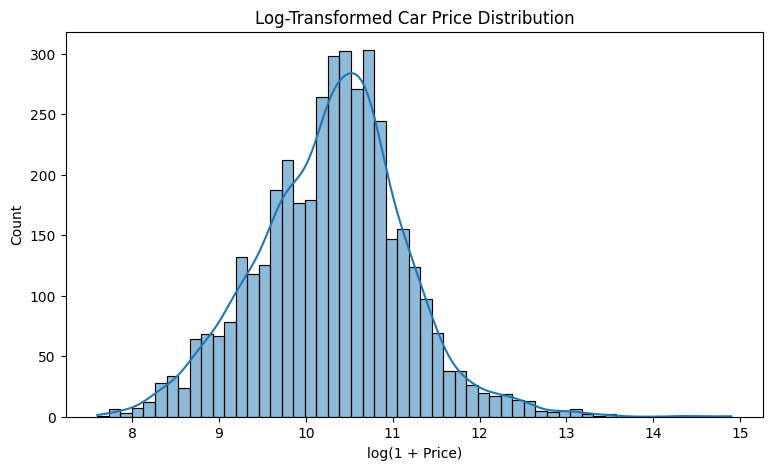

In [33]:
plt.figure(figsize=(9, 5))

sns.histplot(np.log1p(eda_df["price"].dropna()), kde=True)

plt.title("Log-Transformed Car Price Distribution")
plt.xlabel("log(1 + Price)")
plt.show()

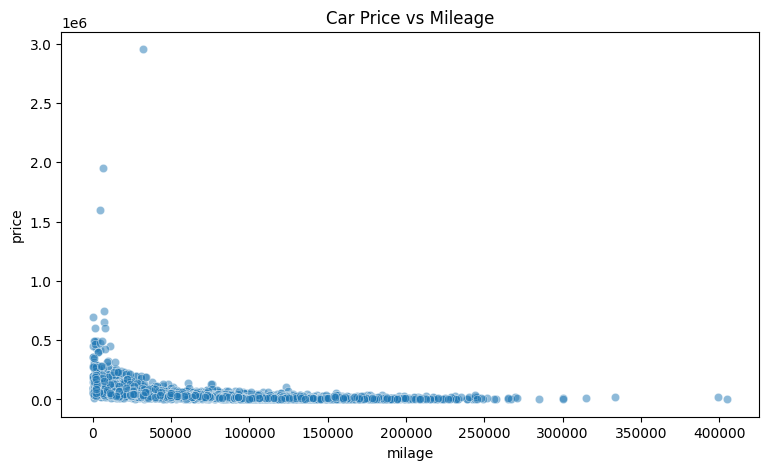

In [34]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=eda_df,
    x="milage",
    y="price",
    alpha=0.5
)

plt.title("Car Price vs Mileage")
plt.show()

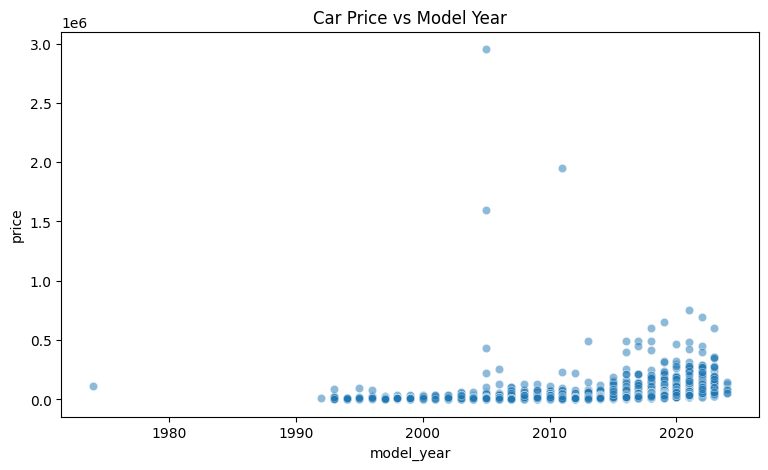

In [35]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=eda_df,
    x="model_year",
    y="price",
    alpha=0.5
)

plt.title("Car Price vs Model Year")
plt.show()

In [36]:
brand_price = (
    eda_df.groupby("brand")["price"]
    .agg(["mean", "median", "count"])
    .sort_values("median", ascending=False)
)

brand_price.head(15)

,mean,median,count
brand,,,
Bugatti,1950995.0,1950995.0,1
Rolls-Royce,370992.727273,399950.0,11
Lamborghini,291233.846154,258000.0,26
Ferrari,243790.666667,249400.0,12
McLaren,213457.5,182450.0,6
Bentley,137553.545455,113990.0,33
Lucid,101966.333333,99000.0,3
Rivian,93138.176471,93500.0,17
Aston,115199.555556,80000.0,9


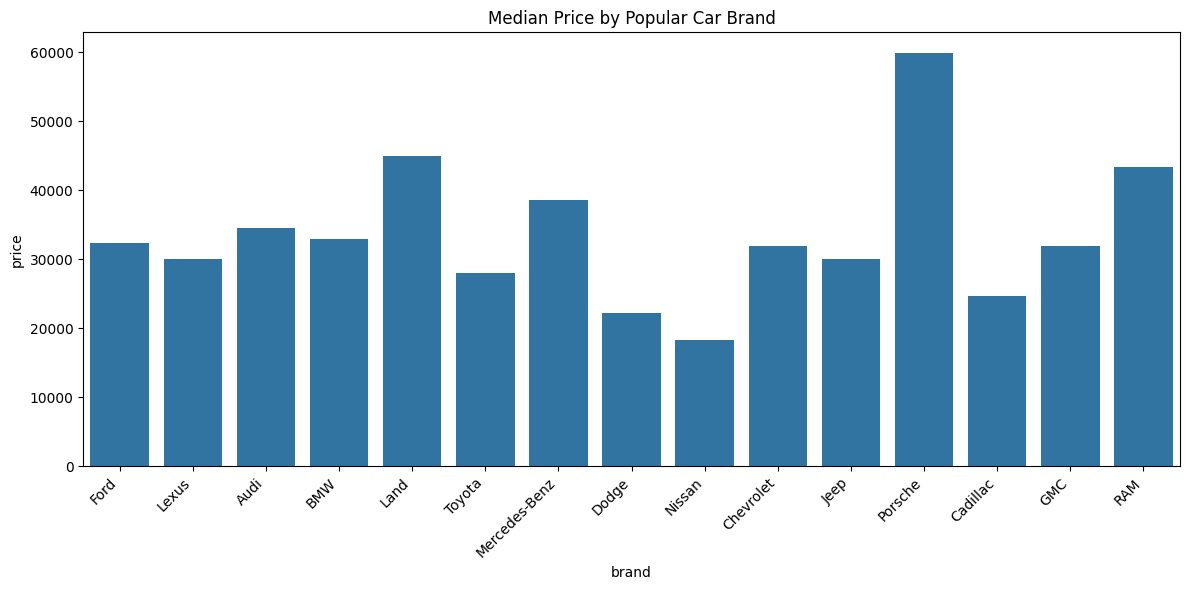

In [37]:
top_brands = (
    eda_df["brand"].value_counts().head(15).index
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=eda_df[eda_df["brand"].isin(top_brands)],
    x="brand",
    y="price",
    estimator="median",
    errorbar=None
)

plt.title("Median Price by Popular Car Brand")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

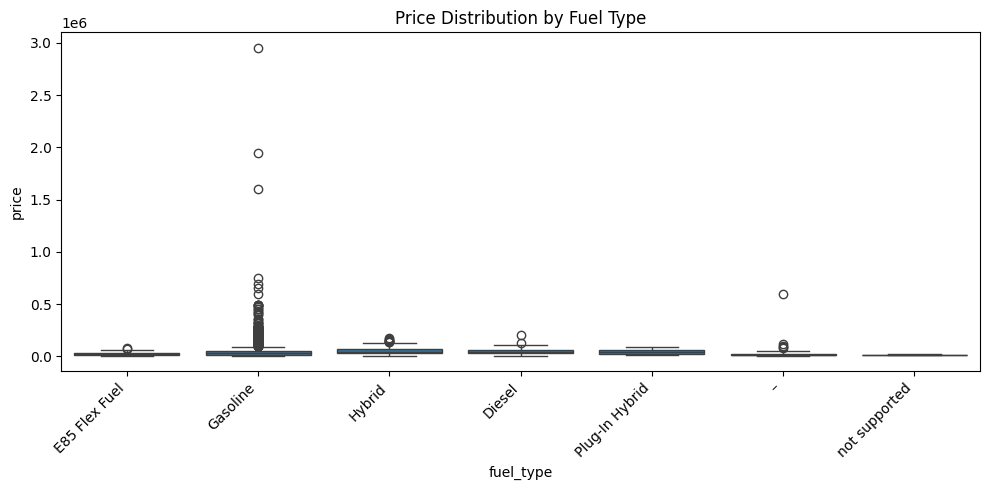

In [38]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=eda_df,
    x="fuel_type",
    y="price"
)

plt.title("Price Distribution by Fuel Type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

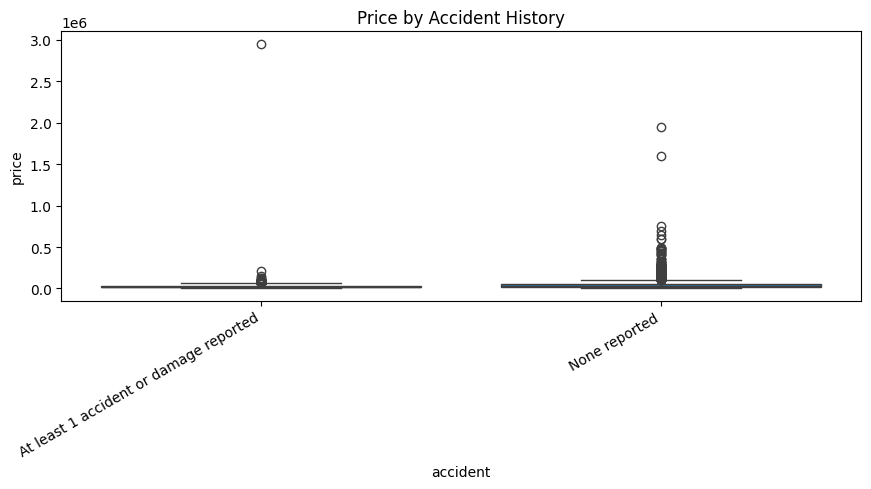

In [39]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=eda_df,
    x="accident",
    y="price"
)

plt.title("Price by Accident History")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

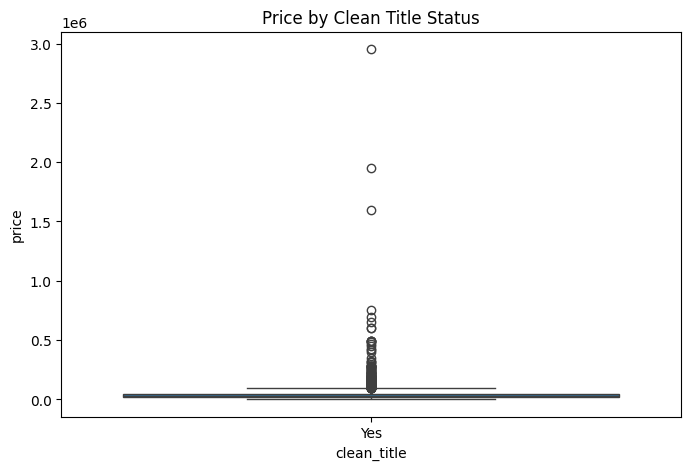

In [40]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="clean_title",
    y="price"
)

plt.title("Price by Clean Title Status")
plt.show()

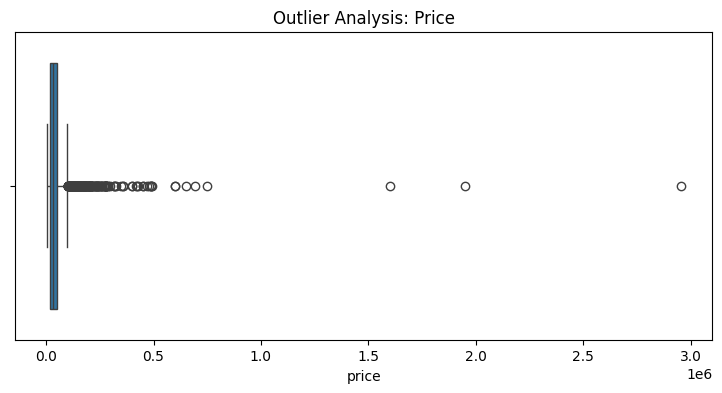

In [41]:
plt.figure(figsize=(9, 4))

sns.boxplot(x=eda_df["price"])

plt.title("Outlier Analysis: Price")
plt.show()

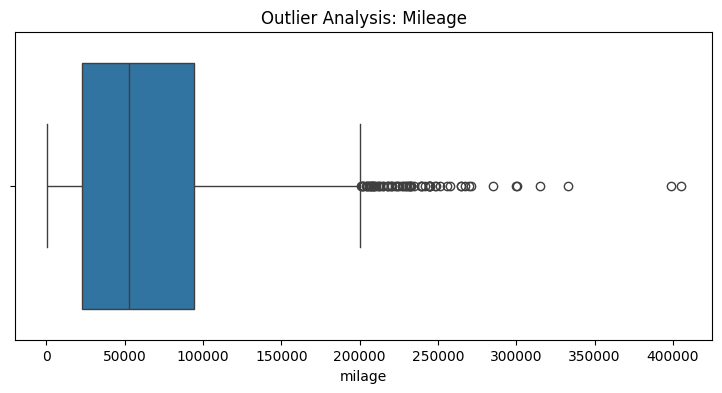

In [42]:
plt.figure(figsize=(9, 4))

sns.boxplot(x=eda_df["milage"])

plt.title("Outlier Analysis: Mileage")
plt.show()

In [43]:
Q1 = eda_df[["price", "milage"]].quantile(0.25)
Q3 = eda_df[["price", "milage"]].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound
})

,Q1,Q3,IQR,Lower Bound,Upper Bound
price,17200.0,49990.0,32790.0,-31985.0,99175.0
milage,23044.0,94100.0,71056.0,-83540.0,200684.0


In [44]:
outlier_counts = (
    (eda_df[["price", "milage"]] < lower_bound) |
    (eda_df[["price", "milage"]] > upper_bound)
).sum()

outlier_counts

price     244
milage     69
dtype: Int64

In [45]:
corr = eda_df[
    ["price", "milage", "model_year"]
].corr()

corr

,price,milage,model_year
price,1.000000,-0.305528,0.199496
milage,-0.305528,1.000000,-0.617720
model_year,0.199496,-0.617720,1.000000


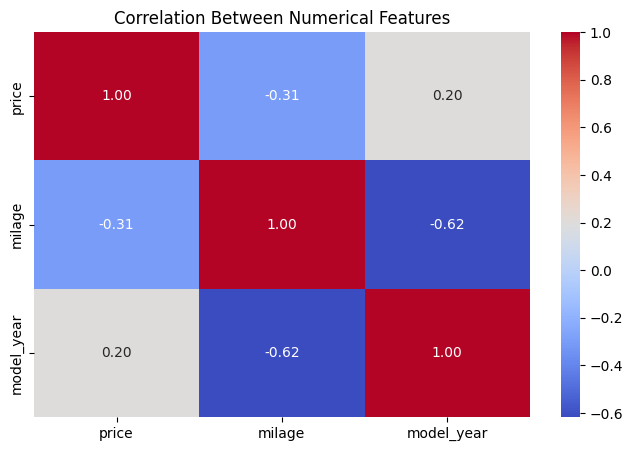

In [46]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.show()

In [47]:
df["engine"].value_counts().head(20)

engine
2.0L I4 16V GDI DOHC Turbo                               52
355.0HP 5.3L 8 Cylinder Engine Gasoline Fuel             48
420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel             47
–                                                        45
300.0HP 3.0L Straight 6 Cylinder Engine Gasoline Fuel    44
240.0HP 2.0L 4 Cylinder Engine Gasoline Fuel             42
285.0HP 3.6L V6 Cylinder Engine Gasoline Fuel            40
5.7L V8 16V MPFI OHV                                     29
340.0HP 3.0L V6 Cylinder Engine Gasoline Fuel            28
3.6L V6 24V MPFI DOHC                                    28
3.6L V6 24V GDI DOHC                                     28
268.0HP 3.5L V6 Cylinder Engine Gasoline Fuel            24
455.0HP 6.2L 8 Cylinder Engine Gasoline Fuel             24
302.0HP 3.5L V6 Cylinder Engine Gasoline Fuel            23
490.0HP 6.2L 8 Cylinder Engine Gasoline Fuel             22
295.0HP 3.5L V6 Cylinder Engine Gasoline Fuel            21
445.0HP 4.4L 8 Cylinder Engine Ga

In [48]:
df["transmission"].value_counts().head(20)

transmission
A/T                               1037
8-Speed A/T                        406
Transmission w/Dual Shift Mode     398
6-Speed A/T                        362
6-Speed M/T                        248
Automatic                          237
7-Speed A/T                        209
8-Speed Automatic                  176
10-Speed A/T                       119
5-Speed A/T                         86
9-Speed A/T                         74
6-Speed Automatic                   73
4-Speed A/T                         72
1-Speed A/T                         64
CVT Transmission                    62
5-Speed M/T                         59
10-Speed Automatic                  56
9-Speed Automatic                   47
M/T                                 40
Automatic CVT                       37
Name: count, dtype: int64

In [49]:
df[["ext_col", "int_col"]].describe(include="all")

,ext_col,int_col
count,4009,4009
unique,319,156
top,Black,Black
freq,905,2025


In [50]:
df[["accident", "clean_title"]].value_counts(dropna=False)

accident                                clean_title
None reported                           Yes            2468
At least 1 accident or damage reported  Yes             945
None reported                           NaN             442
NaN                                     NaN             113
At least 1 accident or damage reported  NaN              41
Name: count, dtype: int64

In [54]:
eda_df[eda_df["price"] <= 0]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price


In [55]:
eda_df[
    (eda_df["model_year"] < 1900) |
    (eda_df["model_year"] > pd.Timestamp.today().year)
]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price


# DATA CLEANING 

In [56]:
clean_df = df.copy()

In [57]:
clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

In [58]:
clean_df.columns

Index(['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine',
       'transmission', 'ext_col', 'int_col', 'accident', 'clean_title',
       'price'],
      dtype='object')

In [59]:
clean_df.duplicated().sum()

np.int64(0)

In [61]:
clean_df.shape

(4009, 12)

In [62]:
clean_df = clean_df.drop_duplicates().copy()

In [63]:
clean_df.shape

(4009, 12)

In [64]:
clean_df["price"] = pd.to_numeric(
    clean_df["price"]
    .astype("string")
    .str.replace(r"[$,]", "", regex=True)
    .str.strip(),
    errors="coerce"
)

In [65]:
clean_df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999


In [68]:
clean_df["price"].describe()

count          4009.0
mean     44553.190322
std      78710.635554
min            2000.0
25%           17200.0
50%           31000.0
75%           49990.0
max         2954083.0
Name: price, dtype: Float64

In [69]:
clean_df["milage"] = pd.to_numeric(
    clean_df["milage"]
    .astype("string")
    .str.replace(r"[^0-9.]", "", regex=True),
    errors="coerce"
)

In [70]:
clean_df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999


In [71]:
clean_df["milage"].describe()

count          4009.0
mean      64717.55101
std      52296.599459
min             100.0
25%           23044.0
50%           52775.0
75%           94100.0
max          405000.0
Name: milage, dtype: Float64

In [72]:
clean_df["model_year"] = pd.to_numeric(
    clean_df["model_year"],
    errors="coerce"
)

In [73]:
clean_df["model_year"].describe()

count    4009.000000
mean     2015.515590
std         6.104816
min      1974.000000
25%      2012.000000
50%      2017.000000
75%      2020.000000
max      2024.000000
Name: model_year, dtype: float64

In [74]:
cat_cols = clean_df.select_dtypes(include="object").columns

for col in cat_cols:
    clean_df[col] = clean_df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

In [75]:
clean_df[clean_df["price"] <= 0]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price


In [76]:
clean_df[clean_df["milage"] < 0]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price


In [77]:
clean_df[
    (clean_df["model_year"] < 1900) |
    (clean_df["model_year"] > pd.Timestamp.today().year)
]

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price


In [78]:
clean_df.isnull().sum().sort_values(ascending=False)

clean_title     596
fuel_type       170
accident        113
brand             0
milage            0
model_year        0
model             0
engine            0
ext_col           0
transmission      0
int_col           0
price             0
dtype: int64

In [79]:
(clean_df.isnull().mean() * 100).round(2).sort_values(ascending=False)

clean_title     14.87
fuel_type        4.24
accident         2.82
brand            0.00
milage           0.00
model_year       0.00
model            0.00
engine           0.00
ext_col          0.00
transmission     0.00
int_col          0.00
price            0.00
dtype: float64

In [80]:
clean_df.shape

(4009, 12)

In [81]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         4009 non-null   object 
 1   model         4009 non-null   object 
 2   model_year    4009 non-null   int64  
 3   milage        4009 non-null   Float64
 4   fuel_type     3839 non-null   object 
 5   engine        4009 non-null   object 
 6   transmission  4009 non-null   object 
 7   ext_col       4009 non-null   object 
 8   int_col       4009 non-null   object 
 9   accident      3896 non-null   object 
 10  clean_title   3413 non-null   object 
 11  price         4009 non-null   Int64  
dtypes: Float64(1), Int64(1), int64(1), object(9)
memory usage: 383.8+ KB


In [82]:
clean_df.dtypes

brand            object
model            object
model_year        int64
milage          Float64
fuel_type        object
engine           object
transmission     object
ext_col          object
int_col          object
accident         object
clean_title      object
price             Int64
dtype: object

In [83]:
clean_df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999


In [84]:
clean_df[clean_df["clean_title"].isnull()].head(10)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999
5,Acura,ILX 2.4L,2016,136397.0,Gasoline,2.4 Liter,F,Silver,Ebony.,None reported,NaN,14798
10,Land,Rover Range Rover Sport 3.0 Supercharged HST,2021,27608.0,Gasoline,V6,Automatic,Fuji White,Pimento / Ebony,None reported,NaN,73897
14,Jaguar,F-TYPE,2020,15903.0,Gasoline,2.0 Liter Supercharged,Automatic,Silver,Black,None reported,NaN,47998
20,Genesis,GV70 3.5T Sport,2023,5400.0,Gasoline,375.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,8-Speed A/T,Green,Beige,NaN,NaN,60000
22,BMW,440 Gran Coupe 440i xDrive,2020,25990.0,Gasoline,3.0 Liter Turbo,Automatic,White,Beige,None reported,NaN,38598
26,Nissan,Sentra SR,2016,96541.0,Gasoline,1.8 Liter,Automatic,Blue,Black,None reported,NaN,13998
32,BMW,i3 120Ah w/Range Extender,2020,35035.0,Hybrid,120 AH,Automatic,Black,Black,None reported,NaN,24998
36,BMW,340 i,2018,44261.0,Gasoline,3.0 Liter Turbo,Automatic,Gray,Black,None reported,NaN,33598


In [85]:
clean_df["clean_title"].value_counts(dropna=False)

clean_title
Yes    3413
NaN     596
Name: count, dtype: int64

In [86]:
clean_df["fuel_type"].value_counts(dropna=False)

fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

In [87]:
clean_df["accident"].value_counts(dropna=False)

accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

In [88]:
missing_cols = ["clean_title", "fuel_type", "accident"]

for col in missing_cols:
    clean_df[col] = clean_df[col].fillna("Unknown")

In [89]:
clean_df.isnull().sum()

brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64

# FEATURE ENGINEERING AND EXTRACTION 

In [90]:
clean_df.shape

(4009, 12)

In [91]:
clean_df["horsepower"] = pd.to_numeric(
    clean_df["engine"].str.extract(
        r"(\d+(?:\.\d+)?)\s*HP",
        expand=False
    ),
    errors="coerce"
)

In [92]:
clean_df["engine_size"] = pd.to_numeric(
    clean_df["engine"].str.extract(
        r"(\d+(?:\.\d+)?)\s*L",
        expand=False
    ),
    errors="coerce"
)

In [93]:
clean_df["cylinders"] = pd.to_numeric(
    clean_df["engine"].str.extract(
        r"(\d+)\s*Cylinder",
        expand=False
    ),
    errors="coerce"
)

In [94]:
clean_df[
    ["engine", "horsepower", "engine_size", "cylinders"]
].head(15)

,engine,horsepower,engine_size,cylinders
0,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,300.0,3.7,6.0
1,3.8L V6 24V GDI DOHC,NaN,3.8,NaN
2,3.5 Liter DOHC,NaN,3.5,NaN
3,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,354.0,3.5,6.0
4,2.0L I4 16V GDI DOHC Turbo,NaN,2.0,NaN
5,2.4 Liter,NaN,2.4,NaN
6,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,292.0,2.0,4.0
7,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,282.0,4.4,8.0
8,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,311.0,3.5,6.0
9,534.0HP Electric Motor Electric Fuel System,534.0,NaN,NaN


In [95]:
clean_df[["horsepower", "engine_size", "cylinders"]].isnull().sum()

horsepower     808
engine_size    217
cylinders      945
dtype: int64

In [96]:
current_year = pd.Timestamp.today().year

clean_df["car_age"] = current_year - clean_df["model_year"]

In [97]:
clean_df[["model_year", "car_age"]].head(10)

,model_year,car_age
0,2013,13
1,2021,5
2,2022,4
3,2015,11
4,2021,5
5,2016,10
6,2017,9
7,2001,25
8,2021,5
9,2020,6


In [98]:
clean_df["transmission_type"] = clean_df["transmission"].str.lower().apply(
    lambda x: "Automatic" if "automatic" in x or "a/t" in x
    else "Manual" if "manual" in x or "m/t" in x
    else "Other"
)

In [99]:
clean_df["transmission_type"].value_counts(dropna=False)

transmission_type
Automatic    3148
Other         489
Manual        372
Name: count, dtype: int64

In [100]:
clean_df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders,car_age,transmission_type
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,300.0,3.7,6.0,13,Automatic
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,NaN,3.8,NaN,5,Automatic
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Unknown,54598,NaN,3.5,NaN,4,Automatic
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500,354.0,3.5,6.0,11,Automatic
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Unknown,34999,NaN,2.0,NaN,5,Automatic


In [101]:
clean_df.shape

(4009, 17)

In [102]:
model_df = clean_df.drop(columns=["engine"]).copy()

In [103]:
model_df.head()

,brand,model,model_year,milage,fuel_type,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders,car_age,transmission_type
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,300.0,3.7,6.0,13,Automatic
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,NaN,3.8,NaN,5,Automatic
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,Automatic,Blue,Black,None reported,Unknown,54598,NaN,3.5,NaN,4,Automatic
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,7-Speed A/T,Black,Black,None reported,Yes,15500,354.0,3.5,6.0,11,Automatic
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,8-Speed Automatic,Glacier White Metallic,Black,None reported,Unknown,34999,NaN,2.0,NaN,5,Automatic


In [104]:
clean_df[["horsepower", "engine_size", "cylinders"]].isnull().sum()

horsepower     808
engine_size    217
cylinders      945
dtype: int64

# DATA VALIDATION

In [105]:
model_df.shape

(4009, 16)

In [106]:
model_df.dtypes

brand                 object
model                 object
model_year             int64
milage               Float64
fuel_type             object
transmission          object
ext_col               object
int_col               object
accident              object
clean_title           object
price                  Int64
horsepower           float64
engine_size          float64
cylinders            float64
car_age                int64
transmission_type     object
dtype: object

In [107]:
model_df.isnull().sum().sort_values(ascending=False)

cylinders            945
horsepower           808
engine_size          217
brand                  0
fuel_type              0
model                  0
model_year             0
milage                 0
int_col                0
ext_col                0
transmission           0
accident               0
price                  0
clean_title            0
car_age                0
transmission_type      0
dtype: int64

In [108]:
model_df[model_df["price"].isnull()]

,brand,model,model_year,milage,fuel_type,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders,car_age,transmission_type


In [109]:
model_df[["horsepower", "engine_size", "cylinders"]].describe()

,horsepower,engine_size,cylinders
count,3201.000000,3792.000000,3064.000000
mean,332.206498,3.684454,6.258159
std,122.258492,1.417481,1.677256
min,70.000000,0.650000,3.000000
25%,248.000000,2.500000,5.000000
50%,310.000000,3.500000,6.000000
75%,400.000000,4.700000,8.000000
max,1020.000000,8.400000,12.000000


In [110]:
model_df.duplicated().sum()

np.int64(0)

In [111]:
model_df = model_df[
    model_df["price"].notna() &
    (model_df["price"] > 0)
].copy()

In [112]:
model_df.shape

(4009, 16)

In [113]:
X = model_df.drop(columns=["price"])
y = model_df["price"]

In [114]:
X.shape

(4009, 15)

In [115]:
y.shape

(4009,)

# PREPROCESSING

In [116]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [117]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

In [118]:
numeric_cols

['model_year', 'milage', 'horsepower', 'engine_size', 'cylinders', 'car_age']

In [119]:
categorical_cols

['brand',
 'model',
 'fuel_type',
 'transmission',
 'ext_col',
 'int_col',
 'accident',
 'clean_title',
 'transmission_type']

In [130]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("car", categorical_pipeline, categorical_cols)
])

In [131]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [132]:
X_train_processed.shape

(3207, 2178)

In [133]:
X_test_processed.shape

(802, 2178)

In [134]:
preprocessor.named_transformers_["car"] \
    .named_steps["encoder"] \
    .get_feature_names_out(categorical_cols)

array(['brand_Acura', 'brand_Alfa', 'brand_Aston', ...,
       'transmission_type_Automatic', 'transmission_type_Manual',
       'transmission_type_Other'], shape=(2172,), dtype=object)

In [135]:
import pandas as pd

encoded_columns = preprocessor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed,
    columns=encoded_columns,
    index=X_train.index
)

X_train_df.head(20)

,num__model_year,num__milage,num__horsepower,num__engine_size,num__cylinders,num__car_age,car__brand_Acura,car__brand_Alfa,car__brand_Aston,car__brand_Audi,...,car__int_col_Yellow,car__int_col_–,car__accident_At least 1 accident or damage reported,car__accident_None reported,car__accident_Unknown,car__clean_title_Unknown,car__clean_title_Yes,car__transmission_type_Automatic,car__transmission_type_Manual,car__transmission_type_Other
2473,0.404894,0.154635,-0.166535,-0.127151,-0.140931,-0.404894,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1338,1.233863,-1.048390,0.231747,1.182258,1.216319,-1.233863,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1613,0.073307,-0.184876,0.865378,-0.490875,-0.140931,-0.073307,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1610,0.239101,0.235722,-0.211795,-0.127151,-0.140931,-0.239101,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
2600,0.404894,-0.595937,-1.533367,-1.218325,-1.498180,-0.404894,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
3945,0.073307,0.574680,-1.343278,-1.509304,-1.498180,-0.073307,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
423,0.239101,-0.289787,0.675289,-0.490875,-0.140931,-0.239101,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3737,1.233863,-1.133845,0.639081,-0.127151,-0.140931,-1.233863,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1096,0.570688,-0.747028,-0.166535,-0.127151,-0.140931,-0.570688,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
506,0.902275,-0.895525,-0.166535,-0.490875,-0.140931,-0.902275,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
